# DC-OPF on the PJM 5-Bus Network: Dispatch, Congestion and LMPs

Economic dispatch (ED) versus network-constrained DC optimal power flow (DC-OPF) on the PJM 5-bus case, with nodal prices (LMPs) and line shadow prices taken from the Pyomo duals and cross-checked against PYPOWER. 

**Contents**
* Summary of Findings
* Network and Data
* Setup
* Economic Dispatch (baseline)
* DC-OPF Model
* Results
* LMPs and Shadow Prices
* Visual Summary
* Conclusion
* Limitations
* References

## Summary of Findings

* **Network constraints change dispatch:** Economic dispatch costs *\$14,810/h*, while network-constrained DC-OPF costs *\$17,479.90/h*.
* **Congestion increases operating cost:** The network-constrained solution costs *\$2,669.90/h* more, an 18.0% increase relative to economic dispatch.
* **One line becomes binding:** Branch 6 (Bus 4 ↔ Bus 5) reaches its 240 MW thermal limit. All other branches remain below their limits.
* **Congestion creates nodal price differences:** LMPs range from *\$10.00/MWh* at Bus 5 to \$39.94/MWh at Bus 4, reflecting the marginal cost of serving additional demand at different locations.
* **Transmission capacity has marginal value:** Branch 6 has a shadow price of approximately *\$62.32/h* for each additional MW of capacity, locally around the current optimum.

The Pyomo/HiGHS results agree with an independent PYPOWER DC-OPF solution for the same test case.

## Network and Data
A standard power systems test case with 5 buses, 5 generators, and 6 transmission lines: https://github.com/power-grid-lib/pglib-opf/blob/master/pglib_opf_case5_pjm.m
<br>
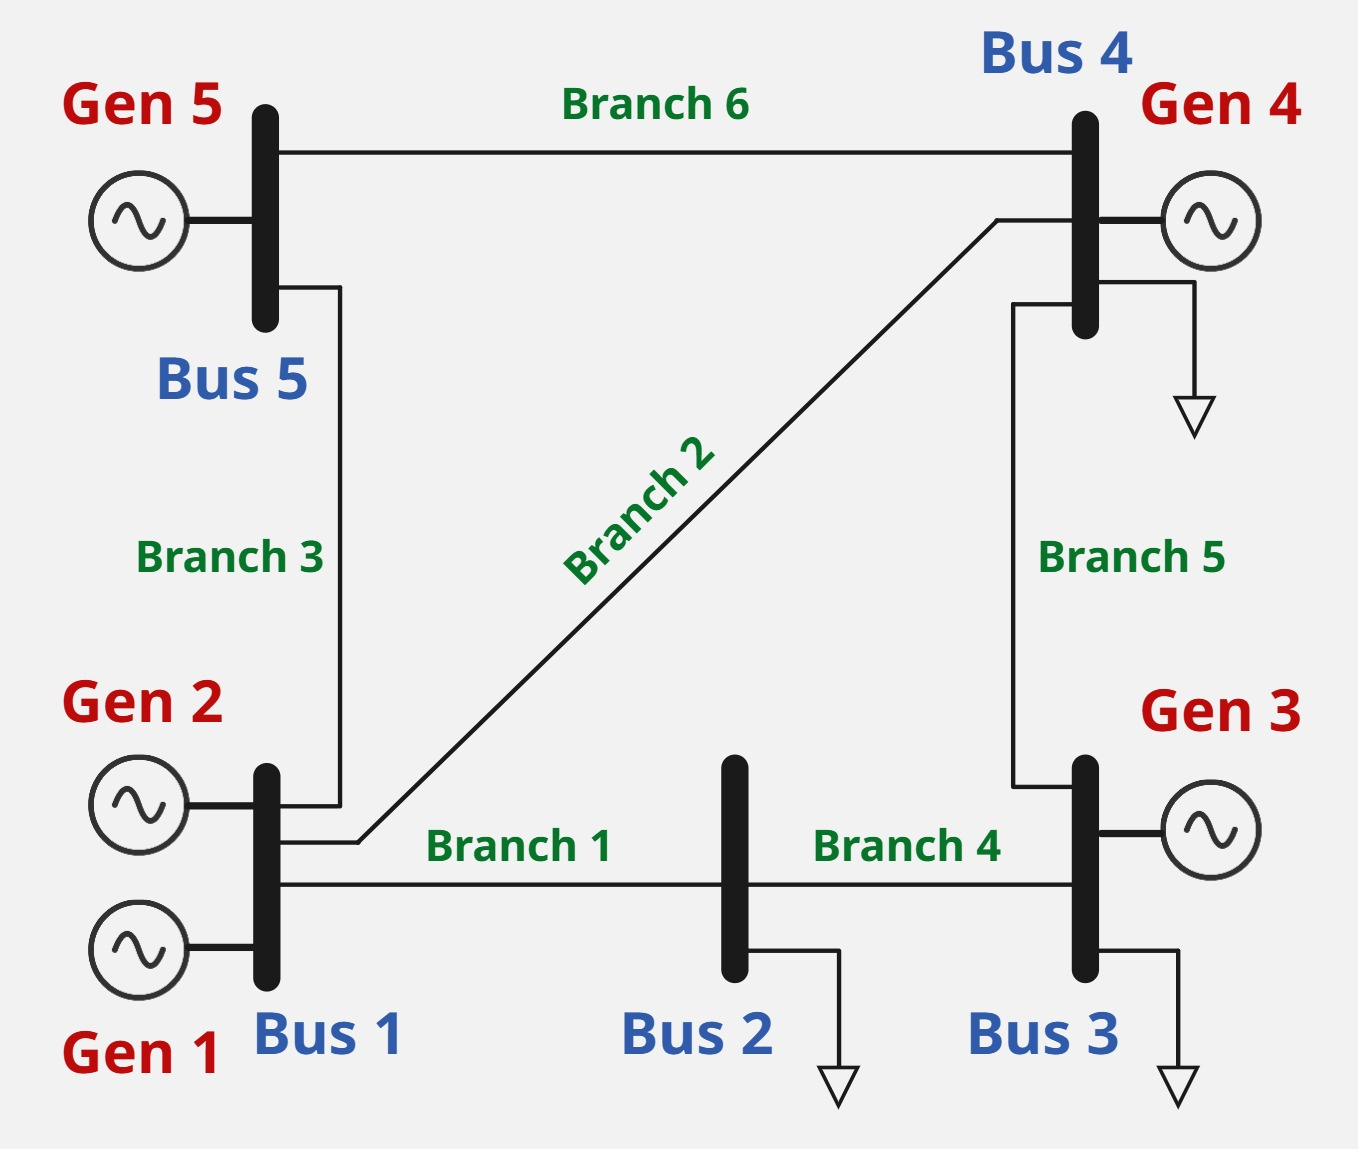


* **Bus data**:
  
| Bus | Type  | Pd (MW) | Qd (MVAr) | Generators connected            | V bounds (p.u.) |
|------|------|---------|-----------|----------------------------------|-----------------|
| 1    | PV    | 0       | 0         | Gen 1, Gen 2   | 0.9 - 1.1       |
| 2    | PQ    | 300     | 98.61     | -                                | 0.9 - 1.1       |
| 3    | PV    | 300     | 98.61     | Gen 3          | 0.9 - 1.1       |
| 4    | Slack | 400     | 131.47    | Gen 4          | 0.9 - 1.1       |
| 5    | PV    | 0       | 0         | Gen 5          | 0.9 - 1.1       |

Total demand: 1000 MW

> Bus 4 is the slack bus, but in DC-OPF that only means its angle is the reference ($\theta = 0$). It gives Gen 4 no special role in dispatch.

* **Generator data**:
  
| Gen | Bus | Cost ($/MWh) | P bounds (MW) | Q bounds (MVAr) |
|-----|-----|---------------|----------------|-----------------|
| 1   | 1   | 14            | 0 - 40         | -30 - 30        |
| 2   | 1   | 15            | 0 - 170        | -127.5 - 127.5  |
| 3   | 3   | 30            | 0 - 520        | -390 - 390      |
| 4   | 4   | 40            | 0 - 200        | -150 - 150      |
| 5   | 5   | 10            | 0 - 600        | -450 - 450      |


* **Branch (line) data**:
  
| Branch | From bus → To bus | r (p.u.) | x (p.u.) | b/2 (p.u.) | Thermal limit (MVA) | Angle bounds (°) |
|--------|---------------------|-----------|-----------|-------------|----------------------|------------------|
| 1      | 1 → 2              | 0.00281   | 0.0281    | 0.00712     | 400                  | -30 to 30        |
| 2      | 1 → 4              | 0.00304   | 0.0304    | 0.00658     | 426                  | -30 to 30        |
| 3      | 1 → 5              | 0.00064   | 0.0064    | 0.03126     | 426                  | -30 to 30        |
| 4      | 2 → 3              | 0.00108   | 0.0108    | 0.01852     | 426                  | -30 to 30        |
| 5      | 3 → 4              | 0.00297   | 0.0297    | 0.00674     | 426                  | -30 to 30        |
| 6      | 4 → 5              | 0.00297   | 0.0297    | 0.00674     | 240                  | -30 to 30        |

Notes on the data:
* Costs are linear. Startup and no-load costs are excluded (commitment is not modelled), and all units are assumed on.
* Angle bounds apply to the voltage angle difference across each branch, $\theta_i - \theta_j$
* Pmin = 0 for all generators is the ideal/simplified case. In reality, Pmin is non-zero due to mechanical stability, thermal constraints and efficiency floors.
* Branch 6 at 240 MVA is the tightest line, and it sits between Bus 5 (cheapest and largest generator) and a load bus.

## Setup

Solver: HiGHS via highs interface. (appsi_highs is also valid and generally faster for repeated solves in the same session.)

Install once with `pip install pyomo highspy numpy pandas matplotlib`.

In [1]:
# Dependencies
# !pip install pyomo highspy numpy pandas matplotlib

In [2]:
import pyomo.environ as pyo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.4f}".format

In [3]:
# network data
baseMVA = 100.0
slackBus = 4

# gens = { gen_id: { bus_id, cost ($/MWh), Pmin (p.u.), Pmax (p.u.) } }
gens = {
    1: {"bus": 1, "c": 14.0, "Pmin": 0.0, "Pmax": 0.40},
    2: {"bus": 1, "c": 15.0, "Pmin": 0.0, "Pmax": 1.70},
    3: {"bus": 3, "c": 30.0, "Pmin": 0.0, "Pmax": 5.20},
    4: {"bus": 4, "c": 40.0, "Pmin": 0.0, "Pmax": 2.00},
    5: {"bus": 5, "c": 10.0, "Pmin": 0.0, "Pmax": 6.00},
}

# buses = { bus_id: { Pd (p.u.) } }
buses = {
    1: {"Pd": 0.0},
    2: {"Pd": 3.00},
    3: {"Pd": 3.00},
    4: {"Pd": 4.00},
    5: {"Pd": 0.0},
}

# network data
# branches = { branch_id:{ from (bus), to (bus), x (p.u.), rate (p.u.), angmax_deg } }
branches = {
    1: {"from": 1, "to": 2, "x": 0.0281, "rate": 4.0, "angmax_deg": 30.0}, 
    2: {"from": 1, "to": 4, "x": 0.0304, "rate": 4.26, "angmax_deg": 30.0},
    3: {"from": 1, "to": 5, "x": 0.0064, "rate": 4.26, "angmax_deg": 30.0}, 
    4: {"from": 2, "to": 3, "x": 0.0108, "rate": 4.26, "angmax_deg": 30.0},
    5: {"from": 3, "to": 4, "x": 0.0297, "rate": 4.26, "angmax_deg": 30.0},
    6: {"from": 4, "to": 5, "x": 0.0297, "rate": 2.4, "angmax_deg": 30.0},
}

In [4]:
demand = sum(buses[i]['Pd'] for i in buses)
gen_ids = sorted(gens)
bus_ids = sorted(buses)
branch_ids = sorted(branches)

## Economic Dispatch (baseline)
ED treats the grid as a single node: minimise total generation cost subject only to *total generation = total demand* and *each unit's bounds*. It gives the cheapest possible dispatch if the network never limited anything, which makes it the reference for measuring what the network costs.

In [5]:
m = pyo.ConcreteModel()

# sets
m.G = pyo.Set(initialize = gen_ids)

# parameters (cost, pmin, pmax)
m.c = pyo.Param(m.G, initialize = {i: gens[i]['c'] for i in gen_ids})
m.pmin = pyo.Param(m.G, initialize = {i: gens[i]['Pmin'] for i in gen_ids})
m.pmax = pyo.Param(m.G, initialize = {i: gens[i]['Pmax'] for i in gen_ids})

# variable (p)
m.p = pyo.Var(
    m.G, 
    domain = pyo.NonNegativeReals,
    bounds = lambda  m, g: (gens[g]['Pmin'], gens[g]['Pmax'])
)

# objective function (minimize: baseMVA * sum(c * p_i))
m.obj = pyo.Objective(
    expr = baseMVA * sum(m.c[i] * m.p[i] for i in m.G),
    sense = pyo.minimize
)

# constraints ( demand constraint)
m.demand_G = pyo.Constraint(
    expr = sum(m.p[i] for i in m.G ) == demand
)

solver = pyo.SolverFactory("highs")

m.dual = pyo.Suffix(direction = pyo.Suffix.IMPORT)

result = solver.solve(m)

# Check solver status
status = result.solver.termination_condition

print(f"Solver status: {status}")  

Solver status: optimal


In [6]:
# generator_dispatch
ed_dispatch = []
for g in gen_ids:
    ed_dispatch.append({
        "Gen": g,
        "Bus": gens[g]['bus'],
        "Pg_pu": pyo.value(m.p[g]),
        "Pg_MW": baseMVA * pyo.value(m.p[g]),
        "Cost_$/MWh": m.c[g],
        "Operating_Cost_$/h": pyo.value(m.p[g])*m.c[g]*baseMVA
    })

pd.DataFrame(ed_dispatch)

,Gen,Bus,Pg_pu,Pg_MW,Cost_$/MWh,Operating_Cost_$/h
0,1,1,0.4000,40.0000,14.0000,560.0000
1,2,1,1.7000,170.0000,15.0000,"2,550.0000"
2,3,3,1.9000,190.0000,30.0000,"5,700.0000"
3,4,4,0.0000,0.0000,40.0000,0.0000
4,5,5,6.0000,600.0000,10.0000,"6,000.0000"


In [7]:
ed_cost = pyo.value(m.obj)
print(f"\nTotal cost: ${ed_cost:.2f}/h")


Total cost: $14810.00/h


In [8]:
# system lambda
lam_ed = m.dual[m.demand_G] / baseMVA
print(f"ED system lambda: ${lam_ed:.2f}/MWh")

ED system lambda: $30.00/MWh


In ED the cheapest unit (Gen 5, *\$10/MWh*) runs at its maximum of 600 MW, Gens 1 and 2 also run at their maximums, and Gen 3 (*\$30/MWh*) is the only partly loaded unit. It therefore sets the system lambda at *\$30/MWh*: one more MW of demand anywhere would be served by Gen 3. 

## DC-OPF Model
DC-OPF adds the transmission network to ED. Variables are $P_g$ for every generator and $\theta_i$ for every bus. 

$$\min \; \sum_g c_g P_g$$

subject to:
* **Generator limits:** $P_g^{min} \le P_g \le P_g^{max}$
  
* **Nodal balance at each bus *i*:** $\sum P_g - P_d = \sum P_{ij}$ for each bus i

* **Line thermal limits:** $-F_{ij}^{\max}  \le \frac{\theta_i - \theta_j}{x_{ij}} \le F_{ij}^{\max} $

* **Branch angle difference limits:** $-\Delta\theta^{max}_{ij} \le \theta_i - \theta_j \le \Delta\theta^{max}_{ij}$

* **Slack bus reference:** $\theta_{slack} = 0$

In [9]:
# helper mappings used in power balance and flow calculations

# 1. bus_to_gens[b] → list of generator IDs at bus b
bus_to_generator = {i: [] for i in bus_ids}
for i, data in gens.items(): # .items → (key, value)
    bus_to_generator[data['bus']].append(i)

# 2. bus_to_branches[b] → list of branch IDs connected to bus b
bus_to_branches = {i: [] for i in bus_ids}
for br, data in branches.items():
    bus_to_branches[data["from"]].append(br)
    bus_to_branches[data["to"]].append(br)

# 3. other_end(br, i) → the bus at the other end of branch br from bus i
def other_end(br, i):
    f = branches[br]['from']
    t = branches[br]['to']
    return t if i == f else f
    

In [10]:
model = pyo.ConcreteModel(name="DC_OPF_5_BUS")

# sets
model.buses = pyo.Set(initialize = bus_ids)
model.gens = pyo.Set(initialize = gen_ids)
model.branches = pyo.Set(initialize = branch_ids)

# parameters (c, Pd, x, rate, angmax)
model.Pd = pyo.Param(model.buses, initialize = {i: buses[i]['Pd'] for i in bus_ids})
model.c = pyo.Param(model.gens, initialize = {g: gens[g]['c'] for g in gen_ids})
model.x = pyo.Param(model.branches, initialize = {br: branches[br]['x'] for br in branch_ids})
model.rate = pyo.Param(model.branches, initialize = {br: branches[br]['rate'] for br in branch_ids})
model.angmax = pyo.Param(model.branches, initialize = {br: np.radians(branches[br]["angmax_deg"]) for br in branch_ids})

# variables (Pg/P, theta)
model.Pg = pyo.Var(
    model.gens,
    bounds = lambda model, g: (gens[g]['Pmin'], gens[g]['Pmax']),
    initialize = lambda model, g: (gens[g]['Pmin'] + gens[g]['Pmax']) / 2
)
model.theta = pyo.Var(
    model.buses,
    bounds = (-np.pi, np.pi),
    initialize = 0.0
)

In [11]:
# objective function (minimize: baseMVA * sum(Pg * c))
model.obj = pyo.Objective(
    expr = baseMVA * sum(model.Pg[g] * model.c[g] for g in model.gens),
    sense = pyo.minimize
)

In [12]:
# constraints (nodal power flow, line limits, reference slack voltage angle, branch angle difference limits)
# dc power flow: (theta_i - theta_j) / x_br
def dc_flow_from_to(m, br, i, j):
    return (m.theta[i] - m.theta[j])/ m.x[br]

# Constraint 1, nodal power flow at a bus: generation - load = flow out from the bus
def power_balance_rule(m, i):
    generation = sum(m.Pg[g] for g in bus_to_generator[i]) # generation in each bus
    load = m.Pd[i]
    flow_out = 0.0
    for br in bus_to_branches[i]:
        j = other_end(br, i)
        flow_out += dc_flow_from_to(m, br, i, j)
    return generation - load - flow_out == 0 

model.power_balance = pyo.Constraint(model.buses, rule=power_balance_rule)

# Constraint 2, line limits of each lines: -rate <= power flow <= rate
def line_limits_rule(m, br):
    rate = m.rate[br]
    i = branches[br]['from']
    j = branches[br]['to']
    return (-rate, dc_flow_from_to(m, br, i, j), rate)

model.line_limits = pyo.Constraint(model.branches, rule=line_limits_rule)

# Constraint 3, theta_slack = 0
model.reference_theta = pyo.Constraint(
    expr = model.theta[slackBus] == 0 # single constraint
) 

# Constraint 4, branch angle difference limits: -angmax <= theta_i - theta_j <= angmax
def angle_limits_rule(m, br):
    angmax = m.angmax[br]
    i = branches[br]["from"]
    j = branches[br]["to"]
    return (-angmax, m.theta[i] - m.theta[j], angmax)

model.angle_limits = pyo.Constraint(model.branches, rule=angle_limits_rule)

In [13]:
# duals
model.dual = pyo.Suffix(direction=pyo.Suffix.IMPORT)

solver_i = pyo.SolverFactory("highs")
result_i = solver_i.solve(model)

print(result_i.solver.termination_condition)

optimal


In [14]:
opf_cost = pyo.value(model.obj)

print(f"DC-OPF total cost: ${opf_cost:,.2f}/h")
print(f"ED total cost:     ${ed_cost:,.2f}/h")

print(f"Cost of congestion: ${opf_cost - ed_cost:,.2f}/h ({(opf_cost - ed_cost) / ed_cost * 100:.1f}%)")

DC-OPF total cost: $17,479.90/h
ED total cost:     $14,810.00/h
Cost of congestion: $2,669.90/h (18.0%)


## Results
### 1. Generator Dispatch

In [15]:
dispatch = []
for g in gen_ids:
    dispatch.append({
    "Gen": g,
    "Bus": gens[g]["bus"],
    "Cost ($/MWh)": gens[g]["c"],
    "ED Pg (MW)": pyo.value(m.p[g]) * baseMVA,
    "DC-OPF Pg (MW)": pyo.value(model.Pg[g]) * baseMVA,
    "Change (MW)": (pyo.value(model.Pg[g]) - pyo.value(m.p[g])) * baseMVA,
    "Pmax (MW)": gens[g]["Pmax"] * baseMVA,
    "DC-OPF operating cost ($/h)": pyo.value(model.Pg[g]) * gens[g]["c"] * baseMVA,
})

pd.DataFrame(dispatch)

,Gen,Bus,Cost ($/MWh),ED Pg (MW),DC-OPF Pg (MW),Change (MW),Pmax (MW),DC-OPF operating cost ($/h)
0,1,1,14.0000,40.0000,40.0000,0.0000,40.0000,560.0000
1,2,1,15.0000,170.0000,170.0000,0.0000,170.0000,"2,550.0000"
2,3,3,30.0000,190.0000,323.4948,133.4948,520.0000,"9,704.8454"
3,4,4,40.0000,0.0000,0.0000,0.0000,200.0000,0.0000
4,5,5,10.0000,600.0000,466.5052,-133.4948,600.0000,"4,665.0515"


Gen 5 gives up 133.5 MW and Gen 3 picks up the same amount. Gens 1 and 2 stay at their maximums and Gen 4 (*\$40/MWh*) is still not needed. Gen 3 carries the highest operating cost in the dispatch.

### 2. Line Flows and Angle Differences

In [16]:
flows = []
for br in branch_ids:
    i = branches[br]["from"]
    j = branches[br]["to"]
    flow_pu = pyo.value(dc_flow_from_to(model, br, i, j)) # returns pyo variables so for numeric value we need pyo.value()
    rate_pu = model.rate[br] # contains pyo parameter so doesn't need to extract numeric value
    dtheta = np.degrees(pyo.value(model.theta[i] - model.theta[j]))
    flows.append({
        "Branch": br,
        "From (Bus)": i,
        "To (Bus)": j,
        "Flow (MW)": flow_pu * baseMVA,
        "Limit (MW)": rate_pu * baseMVA,
        "Loading %": (abs(flow_pu/rate_pu) * 100) if rate_pu > 0 else 0.0,
        "Angle diff (deg)": dtheta,
        "Angle Limit (deg)": branches[br]["angmax_deg"],
        "Angle Loading %": abs(dtheta) / branches[br]["angmax_deg"] * 100,
    })

pd.DataFrame(flows)

,Branch,From (Bus),To (Bus),Flow (MW),Limit (MW),Loading %,Angle diff (deg),Angle Limit (deg),Angle Loading %
0,1,1,2,249.7168,400.0000,62.4292,4.0205,30.0000,13.4016
1,2,1,4,186.7884,426.0000,43.8470,3.2535,30.0000,10.8449
2,3,1,5,-226.5052,426.0000,53.1702,-0.8306,30.0000,2.7686
3,4,2,3,-50.2832,426.0000,11.8036,-0.3111,30.0000,1.0372
4,5,3,4,-26.7884,426.0000,6.2884,-0.4559,30.0000,1.5195
5,6,4,5,-240.0000,240.0000,100.0000,-4.0840,30.0000,13.6135


A negative flow means power moves against the listed from → to direction. Thermal direction does not matter, so loading uses the absolute value (the flow as a share of the line's thermal limit).

* **Branch 6 is at 100% loading**, carrying 240 MW from Bus 5 toward Bus 4. It is the only binding constraint.
* The next most loaded line is Branch 1 at 62.4%; Branch 3, the other path out of Bus 5, is at 53.2%.
* The largest angle difference is $4.08^{\circ}$ (13.6% of the $30^{\circ}$ bound), sot the angle limits are not close to binding in this solution.


> Branch ratings are applied as symmetric MW limits within the lossless DC approximation. The source case gives them in MVA, so this is a simplified representation of thermal capacity.

### 3. Bus Balance and Angles

In [17]:
bus_data = []
for i in bus_ids:
    generation = sum(pyo.value(model.Pg[g]) for g in bus_to_generator[i])
    load = pyo.value(model.Pd[i])
    flow_out = sum(
        pyo.value(dc_flow_from_to(model, br, i, other_end(br, i)))
        for br in bus_to_branches[i]
    )
    bus_data.append({
        "Bus": i,
        "theta (deg)": np.degrees(pyo.value(model.theta[i])),
        "Generation (MW)": generation * baseMVA,
        "Load": (load) * baseMVA,
        "Net flow out": flow_out * baseMVA,
        "Gen - Load - Flow out": (generation - load - flow_out) * baseMVA
    })

pd.DataFrame(bus_data)
    

,Bus,theta (deg),Generation (MW),Load,Net flow out,Gen - Load - Flow out
0,1,3.2535,210.0000,0.0000,210.0000,0.0000
1,2,-0.7670,0.0000,300.0000,-300.0000,0.0000
2,3,-0.4559,323.4948,300.0000,23.4948,0.0000
3,4,-0.0000,0.0000,400.0000,-400.0000,0.0000
4,5,4.0840,466.5052,0.0000,466.5052,-0.0000


Generation − Load − Flow Out is zero at every bus, so the solution is internally consistent. Buses 1 and 5 are net exporters, Buses 2 and 4 are pure importers, and Bus 3 nearly balances itself. Gens 1 and 2 share Bus 1 and therefore share one angle: angle is a property of the bus, not of the generator.

## LMPs and Shadow Prices
Because the DC-OPF is a linear program, the solver also returns the dual of every constraint. The dual of the **nodal power balance** is the bus's **LMP**, and the dual of a **line limit** is that line's **shadow price**.

The raw duals come in *\$/p.u.* because the objective carries `baseMVA`, so they are divided by `baseMVA` to give *\$/MWh*. 

> **Sign convention.** Each balance is written as `generation - load - flow_out == 0`, with every term on the left, so all buses give their dual the same sign. If a balance is written `generation - load == flow_out`, a bus with no generator has a constant on the left, Pyomo swaps the sides internally, and that bus's dual flips sign.
>
> A ranged line limit (`-rate, flow, rate`) has one dual whose sign depends on which side binds, so the code takes `abs(dual) / baseMVA` and the direction comes from the flow sign.

In [18]:
lmp = {i: model.dual[model.power_balance[i]] / baseMVA for i in bus_ids}          # $/MWh
mu = {br: abs(model.dual[model.line_limits[br]]) / baseMVA for br in branch_ids}  # $/h per MW of limit

# reference results from the companion PYPOWER DC-OPF notebook
pp_lmp = np.array([16.97735882, 26.38445952, 30.0, 39.94273632, 10.0])
pp_mu = np.array([0.0, 0.0, 0.0, 0.0, 0.0, 62.32204211])
pp_cost = 17479.896925574154

lmp_df = pd.DataFrame({
    "Bus": bus_ids,
    "LMP Pyomo ($/MWh)": [lmp[i] for i in bus_ids],
    "LMP PYPOWER ($/MWh)": pp_lmp,
})
lmp_df["Difference"] = lmp_df["LMP Pyomo ($/MWh)"] - lmp_df["LMP PYPOWER ($/MWh)"]

mu_df = pd.DataFrame({
    "Branch": branch_ids,
    "Shadow price Pyomo ($/h per MW)": [mu[br] for br in branch_ids],
    "Shadow price PYPOWER": pp_mu,
})

print(f"Cost difference vs PYPOWER: ${abs(opf_cost - pp_cost):.6f}/h")
display(lmp_df)
display(mu_df)

Cost difference vs PYPOWER: $0.000000/h


,Bus,LMP Pyomo ($/MWh),LMP PYPOWER ($/MWh),Difference
0,1,16.9774,16.9774,0.0000
1,2,26.3845,26.3845,-0.0000
2,3,30.0000,30.0000,0.0000
3,4,39.9427,39.9427,0.0000
4,5,10.0000,10.0000,0.0000


,Branch,Shadow price Pyomo ($/h per MW),Shadow price PYPOWER
0,1,0.0000,0.0000
1,2,0.0000,0.0000
2,3,0.0000,0.0000
3,4,0.0000,0.0000
4,5,0.0000,0.0000
5,6,62.3220,62.3220


`Pyomo` and `PYPOWER` agree on cost, LMPs and the shadow price:

* **LMPs**: ED gave one price (*\$30/MWh*) everywhere. In DC-OPF the price ranges from *\$10.00* at Bus 5 (behind the bottleneck, where cheap Gen 5 power is plentiful) to *\$39.94* at Bus 4 (an importer that cheap power cannot reach).
  
* **Marginal units**: Only Gen 3 and Gen 5 can change their output (Gens 1 and 2 are at their maximums and Gen 4 is off), so any extra MW of load is served by those two while Branch 6 stays at its limit. Bus 5 (*\$10*) and Bus 3 (*\$30*) take the cost of the generator at their own bus, and the other buses fall in between. Gen 4 stays off because Bus 4's price (*\$39.94*) is just under its *\$40* offer.

* **Branch 6 shadow price:** about *\$62.32* per hour per additional MW of thermal capacity. Relaxing the limit by 1 MW is expected to reduce operating cost by about that much, provided the set of binding constraints does not change. It is a marginal sensitivity, not a constant saving.

## Visual Summary


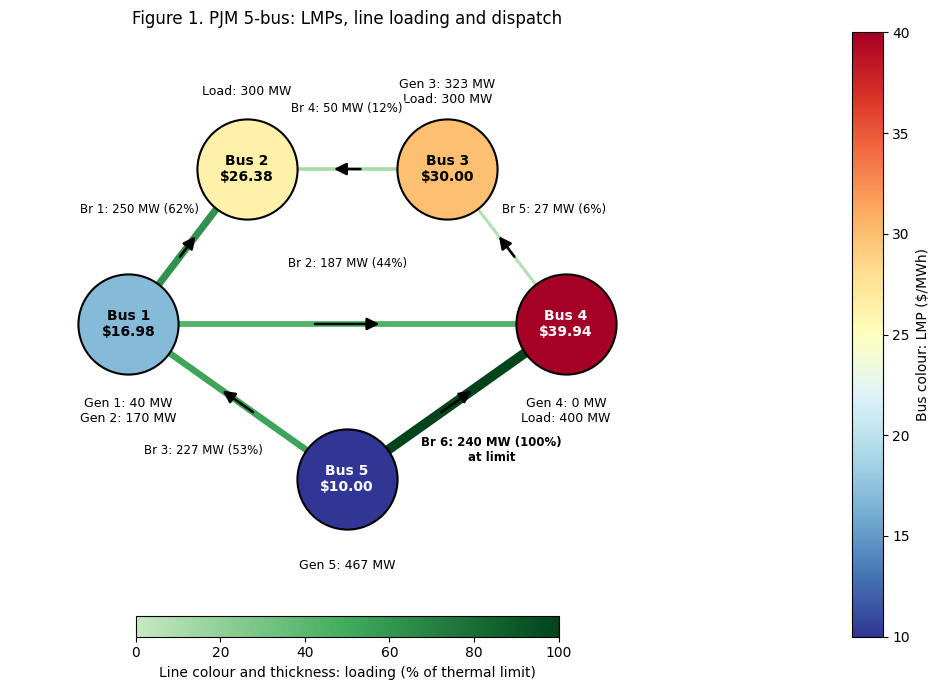

In [19]:
from matplotlib.colors import LinearSegmentedColormap

flows_df = pd.DataFrame(flows)                       # line-flow table
flow_mw = dict(zip(flows_df["Branch"], flows_df["Flow (MW)"]))
loading = dict(zip(flows_df["Branch"], flows_df["Loading %"]))
pg_mw = {g: pyo.value(model.Pg[g]) * baseMVA for g in gen_ids}

pos = {1: (0.0, 0.0), 2: (1.3, 1.7), 3: (3.5, 1.7), 4: (4.8, 0.0), 5: (2.4, -1.7)}
notes = {1: (0.0, -0.95), 2: (1.3, 2.55), 3: (3.5, 2.55), 4: (4.8, -0.95), 5: (2.4, -2.65)}

bus_cmap = plt.cm.RdYlBu_r                                   # bus colour = LMP
bus_norm = plt.Normalize(vmin=10, vmax=40)
line_cmap = LinearSegmentedColormap.from_list("load", ["#c7e9c0", "#41ab5d", "#00441b"])   # line colour = loading
line_norm = plt.Normalize(vmin=0, vmax=100)

fig, ax = plt.subplots(figsize=(11, 7))

for br in branch_ids:
    i, j = branches[br]["from"], branches[br]["to"]
    (x1, y1), (x2, y2) = pos[i], pos[j]
    congested = loading[br] >= 99.9
    col = line_cmap(line_norm(loading[br]))
    ax.plot([x1, x2], [y1, y2], color=col, lw=2 + loading[br] / 100 * 5, zorder=1, solid_capstyle="round")
    # arrow on the line, in the direction of actual flow
    s, e = ((x1, y1), (x2, y2)) if flow_mw[br] >= 0 else ((x2, y2), (x1, y1))
    a = (s[0] + 0.42 * (e[0] - s[0]), s[1] + 0.42 * (e[1] - s[1]))
    b = (s[0] + 0.58 * (e[0] - s[0]), s[1] + 0.58 * (e[1] - s[1]))
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-|>", color="black", lw=1.8, mutation_scale=18), zorder=3)
    # label beside the line, pushed away from the centre of the network
    mx, my = (x1 + x2) / 2, (y1 + y2) / 2
    nx_, ny_ = -(y2 - y1), (x2 - x1)
    norm_ = np.hypot(nx_, ny_); nx_, ny_ = nx_ / norm_, ny_ / norm_
    if nx_ * (mx - 2.4) + ny_ * (my - 0.0) < 0 or (abs(mx - 2.4) < 1e-9 and abs(my) < 1e-9 and ny_ < 0):
        nx_, ny_ = -nx_, -ny_
    label = f"Br {br}: {abs(flow_mw[br]):.0f} MW ({loading[br]:.0f}%)" + ("\nat limit" if congested else "")
    ax.text(mx + 0.66 * nx_, my + 0.66 * ny_, label, ha="center", va="center", fontsize=8.5,
            fontweight="bold" if congested else "normal", zorder=4,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))

for i in bus_ids:
    x, y = pos[i]
    ax.scatter([x], [y], s=5200, color=bus_cmap(bus_norm(lmp[i])), edgecolor="black", linewidth=1.5, zorder=5)
    txt_col = "white" if (lmp[i] < 15 or lmp[i] > 35) else "black"
    ax.text(x, y, f"Bus {i}\n${lmp[i]:.2f}", ha="center", va="center", fontsize=10, fontweight="bold", color=txt_col, zorder=6)
    lines = [f"Gen {g}: {pg_mw[g]:.0f} MW" for g in bus_to_generator[i]]
    if buses[i]["Pd"] > 0:
        lines.append(f"Load: {buses[i]['Pd'] * baseMVA:.0f} MW")
    nx_, ny_ = notes[i]
    ax.text(nx_, ny_, "\n".join(lines), ha="center", va="center", fontsize=9, color="black")

cb1 = fig.colorbar(plt.cm.ScalarMappable(norm=bus_norm, cmap=bus_cmap), ax=ax, fraction=0.035, pad=0.02)
cb1.set_label("Bus colour: LMP ($/MWh)")
cb2 = fig.colorbar(plt.cm.ScalarMappable(norm=line_norm, cmap=line_cmap), ax=ax, orientation="horizontal",
                   fraction=0.035, pad=0.0, shrink=0.5)
cb2.set_label("Line colour and thickness: loading (% of thermal limit)")

ax.set_xlim(-1.3, 6.1); ax.set_ylim(-3.2, 3.2)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Figure 1. PJM 5-bus: LMPs, line loading and dispatch", fontsize=12)
plt.tight_layout()
plt.show()

**Figure 1** shows the network. Bus colour and the dollar value inside each bus are its LMP; line colour and thickness show loading (darkest and thickest = at its limit); arrows show the direction of power flow; and the text beside each bus gives its generation and load. Only Branch 6 is at its limit.

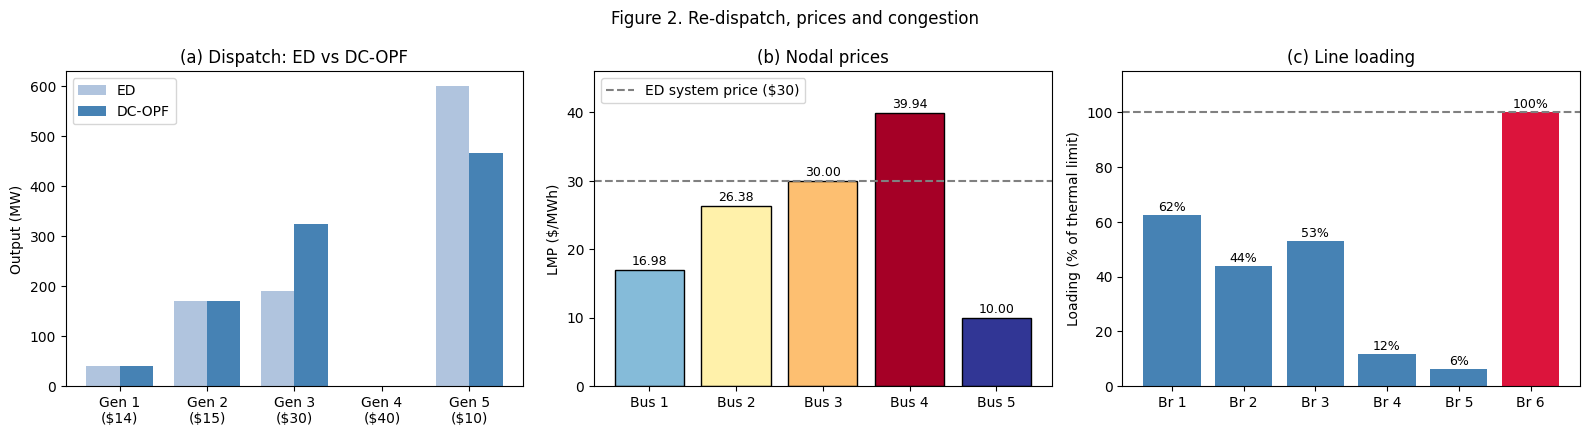

In [20]:
dispatch_df = pd.DataFrame(dispatch)                 # dispatch table (ED vs DC-OPF)
flows_df = pd.DataFrame(flows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

# (a) dispatch: ED vs DC-OPF
w = 0.38
xg = np.arange(len(gen_ids))
axes[0].bar(xg - w / 2, dispatch_df["ED Pg (MW)"], w, label="ED", color="lightsteelblue")
axes[0].bar(xg + w / 2, dispatch_df["DC-OPF Pg (MW)"], w, label="DC-OPF", color="steelblue")
axes[0].set_xticks(xg)
axes[0].set_xticklabels([f"Gen {g}\n(${gens[g]['c']:.0f})" for g in gen_ids])
axes[0].set(ylabel="Output (MW)", title="(a) Dispatch: ED vs DC-OPF")
axes[0].legend()

# (b) LMP per bus
vals = [lmp[i] for i in bus_ids]
axes[1].bar([f"Bus {i}" for i in bus_ids], vals, color=[bus_cmap(bus_norm(v)) for v in vals], edgecolor="black")
axes[1].axhline(lam_ed, ls="--", color="gray", label=f"ED system price (${lam_ed:.0f})")
for k, v in enumerate(vals):
    axes[1].text(k, v + 0.7, f"{v:.2f}", ha="center", fontsize=9)
axes[1].set(ylabel="LMP ($/MWh)", title="(b) Nodal prices", ylim=(0, 46))
axes[1].legend(loc="upper left")

# (c) line loading
ld = list(flows_df["Loading %"])
axes[2].bar([f"Br {br}" for br in flows_df["Branch"]], ld, color=["crimson" if l >= 99.9 else "steelblue" for l in ld])
axes[2].axhline(100, ls="--", color="gray")
for k, v in enumerate(ld):
    axes[2].text(k, v + 1.5, f"{v:.0f}%", ha="center", fontsize=9)
axes[2].set(ylabel="Loading (% of thermal limit)", title="(c) Line loading", ylim=(0, 115))

fig.suptitle("Figure 2. Re-dispatch, prices and congestion", fontsize=12)
plt.tight_layout()
plt.show()

**Figure 2** compares ED with DC-OPF dispatch, the LMP at each bus, and the loading of each line.

## Conclusion

Generator costs alone do not determine the least-cost feasible dispatch. Here the Branch 6 limit forces 133.5 MW of cheap Gen 5 output to be replaced by Gen 3, adds *\$2,669.90/h* (18.0%) to the operating cost, and splits the single ED price into nodal prices from *\$10.00* to *\$39.94/MWh*. The dual of the binding line (*\$62.32/h* per MW) shows where extra transmission capacity would be worth most, and the Pyomo duals match PYPOWER.


## Limitations

**Simplifications in this model**

* **Simplified network physics:** The lossless DC approximation ignores transmission losses, reactive power, and voltage-magnitude constraints.
* **Limited operational scope:** The model considers a single-period base case without generator ramping, reserve requirements, unit commitment, or N−1 security constraints.
* **Simplified market representation:** Linear generation costs and zero minimum generator outputs omit several real-world generator and market constraints. The resulting locational marginal prices (LMPs) are model-derived nodal prices, not actual PJM day-ahead market prices.

Future work could extend the formulation to multi-period dispatch with generator operating constraints and incorporate contingency analysis to investigate how these factors affect optimal dispatch, congestion, and LMPs.

## References

* **Test system:** IEEE PES Power Grid Library, [`pglib_opf_case5_pjm`](https://github.com/power-grid-lib/pglib-opf), version 23.07. Based on F. Li and R. Bo, “Small Test Systems for Power System Economic Studies,” IEEE PES General Meeting, 2010.
* **Reference implementation:** PYPOWER notebook used to validate the DC-OPF dispatch and objective value. [View the PYPOWER notebook](02_dcopf_pypower_reference.ipynb).
* **Theory and learning resources:** see the companion note *ED, DC-OPF, and AC-OPF*.
